# 1. Data Preparation
    - combine datasets
    - create timestamp
    - sort
    - labels
    - basic sanity checks

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# We load our finalized processed dataset directly from Google Drive
import pandas as pd
import os

network_dir = '/content/drive/MyDrive/Network'
combined_csv_path = f'{network_dir}/texbat_combined_dataset.csv'

if os.path.exists(combined_csv_path):
    combined_df = pd.read_csv(combined_csv_path)
    print(f"Successfully loaded combined dataset directly from Drive. Shape: {combined_df.shape}")
    display(combined_df.head())
else:
    print(f"Could not locate {combined_csv_path}. Please make sure your Drive is mounted.")

Successfully loaded combined dataset directly from Drive. Shape: (120562, 18)


,rrt_week,rrt_sec,ort_week,ort_whole_sec,ort_frac_sec,doppler_hz,carrier_phase,pseudorange,cn0,valid_flag,error_indicator,channel_status,signal_type,txid,error_indicator_int,spoofing_flag_from_receiver,label,scenario
0,0.0,26.800556,1705.0,477906.0,0.169,766.088501,-20767.900704,2.098547e+07,50.934761,1.0,0.0,6.0,0.0,3.0,0,0,0,cleanStatic
1,0.0,26.800556,1705.0,477906.0,0.169,-522.856140,13786.257029,2.191315e+07,48.713936,1.0,0.0,6.0,0.0,6.0,0,0,0,cleanStatic
2,0.0,26.800556,1705.0,477906.0,0.169,1853.168945,-49676.470322,2.268528e+07,48.678989,1.0,0.0,6.0,0.0,7.0,0,0,0,cleanStatic
3,0.0,26.800556,1705.0,477906.0,0.169,632.961731,-17184.997980,2.393206e+07,43.262276,1.0,0.0,6.0,0.0,10.0,0,0,0,cleanStatic
4,0.0,26.800556,1705.0,477906.0,0.169,1916.854004,-51250.018610,2.603661e+07,35.100704,1.0,0.0,6.0,0.0,11.0,0,0,0,cleanStatic


#2. Feature Engineering

In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve

ONSET = {"ds2": 477992, "ds3": 478001, "ds7": 478036}
FEATSETS = {
    "full": ["cn0_zscore_per_satellite", "cn0_rolling_std", "cn0_diff",
             "doppler_rolling_std", "doppler_diff"],
    "no_z": ["cn0_rolling_std", "cn0_diff", "doppler_rolling_std", "doppler_diff"],
}

all_df = combined_df.copy()
all_df["t"] = all_df["ort_whole_sec"] + all_df["ort_frac_sec"]
all_df = all_df.sort_values(["scenario", "txid", "t"]).reset_index(drop=True)

def add_rolling(g):
    g = g.copy()
    g["cn0_rolling_std"] = g["cn0"].rolling(10, min_periods=1).std().fillna(0)
    g["cn0_diff"] = g["cn0"].diff().fillna(0)
    g["doppler_rolling_std"] = g["doppler_hz"].rolling(10, min_periods=1).std().fillna(0)
    g["doppler_diff"] = g["doppler_hz"].diff().fillna(0)
    return g

all_df = all_df.groupby(["scenario", "txid"], group_keys=False).apply(add_rolling)

def make_baseline(train_normal):
    b = train_normal.groupby("txid")["cn0"].agg(["mean", "std"])
    b.columns = ["cn0_mu", "cn0_sd"]
    return b

def add_z(df, b):
    out = df.join(b, on="txid")
    out["cn0_zscore_per_satellite"] = (out["cn0"] - out["cn0_mu"]) / out["cn0_sd"]
    return out.dropna(subset=["cn0_zscore_per_satellite"])

def fit_detector(train_normal, fs="full", pct=5):
    feats = FEATSETS[fs]
    b = make_baseline(train_normal)
    tr = add_z(train_normal, b)
    sc = StandardScaler().fit(tr[feats])
    m = IsolationForest(n_estimators=200, random_state=42).fit(sc.transform(tr[feats]))
    thr = np.percentile(m.decision_function(sc.transform(tr[feats])), pct)
    return dict(b=b, sc=sc, m=m, thr=thr, feats=feats)

def score(det, df):
    d = add_z(df, det["b"])
    return d, det["m"].decision_function(det["sc"].transform(d[det["feats"]]))


normal_tr_scn = all_df[all_df.scenario.isin(["cleanStatic", "ds2", "ds3"]) & (all_df.label == 0)]
print(all_df.groupby(["scenario", "label"]).size())

scenario     label
cleanStatic  0        30030
ds2          0         6020
             1        23531
ds3          0         6650
             1        23461
ds7          0         9100
             1        21770
dtype: int64


/tmp/ipykernel_3235/3141476009.py:26: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  all_df = all_df.groupby(["scenario", "txid"], group_keys=False).apply(add_rolling)


#3. Experimental Setup

In [4]:
def fpr_report(train, test, name):
    res = {}
    for p in (5, 20):
        det = fit_detector(train, "full", p)
        d, s = score(det, test)
        res[f"FPR@p{p}"] = round((s < det["thr"]).mean(), 3)
    print(name, res, "| n_train =", len(train), "n_test =", len(test))

# A) random row split
tr_r, te_r = train_test_split(normal_tr_scn, test_size=0.3, random_state=42)
fpr_report(tr_r, te_r, "RANDOM  ")

# B) temporal split
tr_parts, te_parts = [], []
for scn, g in normal_tr_scn.groupby("scenario"):
    t_cut = g.t.min() + 0.7 * (g.t.max() - g.t.min())
    tr_parts.append(g[g.t < t_cut - 2])
    te_parts.append(g[g.t >= t_cut])
fpr_report(pd.concat(tr_parts), pd.concat(te_parts), "TEMPORAL")

RANDOM   {'FPR@p5': np.float64(0.05), 'FPR@p20': np.float64(0.199)} | n_train = 29890 n_test = 12810
TEMPORAL {'FPR@p5': np.float64(0.046), 'FPR@p20': np.float64(0.255)} | n_train = 29456 n_test = 12824


In [5]:
def evaluate(test_scn, train_scns, fs="full", pct=5, guard=0, tag=""):
    train_normal = all_df[all_df.scenario.isin(train_scns) & (all_df.label == 0)]
    det = fit_detector(train_normal, fs, pct)
    test = all_df[all_df.scenario == test_scn]
    if guard > 0:
        o = ONSET[test_scn]
        test = test[(test.t < o - guard) | (test.t > o + guard)]
    d, s = score(det, test)
    y = d["label"].values
    fpr, tpr, _ = roc_curve(y, -s)
    flagged = s < det["thr"]
    return {"test": test_scn, "train": "+".join(train_scns), "feats": fs, "guard": guard, "tag": tag,
            "AUC": round(roc_auc_score(y, -s), 3),
            "R@FPR1%": round(tpr[fpr <= 0.01].max(), 2),
            "R@FPR5%": round(tpr[fpr <= 0.05].max(), 2),
            "R@FPR10%": round(tpr[fpr <= 0.10].max(), 2),
            f"FPR@p{pct}": round(flagged[y == 0].mean(), 3),
            f"Recall@p{pct}": round(flagged[y == 1].mean(), 3)}

rows = []
rows.append(evaluate("ds2", ["cleanStatic", "ds2", "ds3"], tag="seen"))
rows.append(evaluate("ds3", ["cleanStatic", "ds2", "ds3"], tag="seen"))

rows.append(evaluate("ds2", ["cleanStatic", "ds3"], tag="unseen"))
rows.append(evaluate("ds3", ["cleanStatic", "ds2"], tag="unseen"))
rows.append(evaluate("ds7", ["cleanStatic", "ds2", "ds3"], tag="unseen"))

rows.append(evaluate("ds2", ["cleanStatic", "ds3"], fs="no_z", tag="unseen"))
rows.append(evaluate("ds3", ["cleanStatic", "ds2"], fs="no_z", tag="unseen"))
rows.append(evaluate("ds7", ["cleanStatic", "ds2", "ds3"], fs="no_z", tag="unseen"))

rows.append(evaluate("ds2", ["cleanStatic", "ds3"], guard=10, tag="unseen+guard"))
rows.append(evaluate("ds3", ["cleanStatic", "ds2"], guard=30, tag="unseen+guard"))

pd.set_option("display.width", 250)
results_v2 = pd.DataFrame(rows)
results_v2

,test,train,feats,guard,tag,AUC,R@FPR1%,R@FPR5%,R@FPR10%,FPR@p5,Recall@p5
0,ds2,cleanStatic+ds2+ds3,full,0,seen,0.901,0.05,0.32,0.49,0.066,0.368
1,ds3,cleanStatic+ds2+ds3,full,0,seen,0.846,0.07,0.24,0.41,0.068,0.299
2,ds2,cleanStatic+ds3,full,0,unseen,0.898,0.05,0.31,0.49,0.068,0.363
3,ds3,cleanStatic+ds2,full,0,unseen,0.840,0.07,0.23,0.38,0.076,0.304
4,ds7,cleanStatic+ds2+ds3,full,0,unseen,0.705,0.01,0.10,0.20,0.082,0.162
5,ds2,cleanStatic+ds3,no_z,0,unseen,0.632,0.01,0.17,0.27,0.066,0.203
6,ds3,cleanStatic+ds2,no_z,0,unseen,0.594,0.03,0.13,0.21,0.068,0.164
7,ds7,cleanStatic+ds2+ds3,no_z,0,unseen,0.529,0.01,0.05,0.11,0.062,0.067
8,ds2,cleanStatic+ds3,full,10,unseen+guard,0.912,0.03,0.32,0.56,0.061,0.357
9,ds3,cleanStatic+ds2,full,30,unseen+guard,0.858,0.03,0.24,0.48,0.064,0.292


In [6]:
# New cell: add rolling-mean z-score features; redefine add_z (overrides Cell A's version)
def add_z(df, b, windows=(5, 25, 50)):
    out = df.join(b, on="txid")
    out["cn0_zscore_per_satellite"] = (out["cn0"] - out["cn0_mu"]) / out["cn0_sd"]
    out = out.dropna(subset=["cn0_zscore_per_satellite"])
    # Causal rolling mean (past samples only), computed per (scenario, txid) in time order
    for w in windows:
        out[f"z_roll_mean_{w}"] = (
            out.groupby(["scenario", "txid"])["cn0_zscore_per_satellite"]
               .transform(lambda s: s.rolling(w, min_periods=1).mean())
        )
    return out

FEATSETS.update({
    "z_only":        ["cn0_zscore_per_satellite"],
    "z_roll5":       ["z_roll_mean_5"],
    "z_roll25":      ["z_roll_mean_25"],
    "z_roll50":      ["z_roll_mean_50"],
    "full_plus_z25": FEATSETS["full"] + ["z_roll_mean_25"],
})

rows = []
for fs in ["full", "z_only", "z_roll5", "z_roll25", "z_roll50", "full_plus_z25"]:
    rows.append(evaluate("ds2", ["cleanStatic", "ds3"], fs=fs, tag="unseen"))
    rows.append(evaluate("ds3", ["cleanStatic", "ds2"], fs=fs, tag="unseen"))

results_e7 = pd.DataFrame(rows)
results_e7[["test", "feats", "AUC", "R@FPR1%", "R@FPR5%", "R@FPR10%", "FPR@p5", "Recall@p5"]]

,test,feats,AUC,R@FPR1%,R@FPR5%,R@FPR10%,FPR@p5,Recall@p5
0,ds2,full,0.898,0.05,0.31,0.49,0.068,0.363
1,ds3,full,0.840,0.07,0.23,0.38,0.076,0.304
2,ds2,z_only,0.986,0.15,0.98,0.99,0.075,0.988
3,ds3,z_only,0.879,0.55,0.69,0.77,0.066,0.717
4,ds2,z_roll5,0.985,0.16,0.98,0.99,0.073,0.988
5,ds3,z_roll5,0.884,0.57,0.70,0.78,0.066,0.727
6,ds2,z_roll25,0.982,0.16,0.98,0.99,0.067,0.986
7,ds3,z_roll25,0.891,0.63,0.74,0.80,0.053,0.747
8,ds2,z_roll50,0.991,0.79,0.98,0.99,0.061,0.985
9,ds3,z_roll50,0.895,0.62,0.75,0.81,0.057,0.759


In [7]:
# trivial baseline without Isolation Forest: score = rolling mean of z (higher = more suspicious)
def evaluate_simple(test_scn, train_scns, window=25, one_sided=True):
    train_normal = all_df[all_df.scenario.isin(train_scns) & (all_df.label == 0)]
    b = make_baseline(train_normal)
    test = add_z(all_df[all_df.scenario == test_scn], b, windows=(window,))
    y = test["label"].values
    s = test[f"z_roll_mean_{window}"].values
    if not one_sided:
        s = np.abs(s)
    fpr, tpr, _ = roc_curve(y, s)
    return {"test": test_scn, "window": window, "one_sided": one_sided,
            "AUC": round(roc_auc_score(y, s), 3),
            "R@FPR1%": round(tpr[fpr <= 0.01].max(), 2),
            "R@FPR5%": round(tpr[fpr <= 0.05].max(), 2),
            "R@FPR10%": round(tpr[fpr <= 0.10].max(), 2)}

rows = []
for w in (1, 5, 25, 50):
    for one_sided in (True, False):
        rows.append(evaluate_simple("ds2", ["cleanStatic", "ds3"], w, one_sided))
        rows.append(evaluate_simple("ds3", ["cleanStatic", "ds2"], w, one_sided))
pd.DataFrame(rows)

,test,window,one_sided,AUC,R@FPR1%,R@FPR5%,R@FPR10%
0,ds2,1,True,0.807,0.79,0.80,0.81
1,ds3,1,True,0.186,0.10,0.11,0.12
2,ds2,1,False,0.994,0.92,0.98,0.99
3,ds3,1,False,0.880,0.55,0.70,0.77
4,ds2,5,True,0.807,0.79,0.80,0.80
5,ds3,5,True,0.185,0.10,0.11,0.12
6,ds2,5,False,0.994,0.93,0.98,0.99
7,ds3,5,False,0.882,0.57,0.70,0.78
8,ds2,25,True,0.807,0.79,0.80,0.80
9,ds3,25,True,0.183,0.10,0.11,0.12


#4. CN0 Representation Experiments

In [8]:
# Diagnostic: direction and size of the C/N0 shift per satellite (baseline built from the OTHER scenarios)
rows = []
for test_scn, train_scns in [("ds2", ["cleanStatic", "ds3"]), ("ds3", ["cleanStatic", "ds2"])]:
    train_normal = all_df[all_df.scenario.isin(train_scns) & (all_df.label == 0)]
    b = make_baseline(train_normal)
    d = add_z(all_df[all_df.scenario == test_scn], b, windows=(25,))
    g = d.groupby(["txid", "label"])["cn0_zscore_per_satellite"].mean().unstack()
    g.columns = ["mean_z_normal", "mean_z_attack"]
    g["shift"] = g["mean_z_attack"] - g["mean_z_normal"]
    g["scenario"] = test_scn
    rows.append(g.reset_index())

diag = pd.concat(rows)
print(diag.round(2).to_string())
print()
print(diag.groupby("scenario")[["mean_z_normal", "mean_z_attack", "shift"]].mean().round(2))

     txid  mean_z_normal  mean_z_attack   shift scenario
0     3.0          -0.02          19.30   19.32      ds2
1     6.0          -0.07          13.92   14.00      ds2
2     7.0           0.26           9.37    9.11      ds2
3    10.0          -1.06           4.93    5.99      ds2
4    11.0          -0.12          -2.65   -2.54      ds2
5    13.0           1.03          16.66   15.62      ds2
6    16.0           0.18           8.39    8.21      ds2
7    19.0          -0.59          10.29   10.89      ds2
8    20.0          -0.40           7.07    7.47      ds2
9    23.0           0.13          21.62   21.49      ds2
10   30.0           0.86           5.01    4.15      ds2
11   32.0           0.38           4.30    3.92      ds2
12  133.0          -0.12        -122.22 -122.10      ds2
13  138.0           0.73        -139.67 -140.40      ds2
0     3.0          -0.27          -2.58   -2.32      ds3
1     6.0          -0.35          -5.89   -5.54      ds3
2     7.0          -0.28       

In [9]:
# real C/N0 noise level per satellite, from NORMAL rows only
normal_rows = all_df[(all_df.label == 0) & all_df.scenario.isin(["cleanStatic", "ds2", "ds3"])]
print(normal_rows.groupby(["txid", "scenario"])["cn0"].agg(["mean", "std"]).unstack().round(2).to_string())
print()
print("Baseline used by the detector (all training normals pooled):")
print(make_baseline(normal_rows).round(3).to_string())

                mean                       std            
scenario cleanStatic    ds2    ds3 cleanStatic   ds2   ds3
txid                                                      
3.0            51.00  50.98  50.94        0.21  0.27  0.18
6.0            48.78  48.74  48.67        0.30  0.29  0.20
7.0            48.26  48.35  48.16        0.41  0.34  0.47
10.0           43.78  42.68  42.75        0.82  0.35  0.44
11.0           37.68  37.40  37.56        2.00  3.34  3.21
13.0           51.32  51.61  51.48        0.24  0.38  0.25
16.0           49.73  49.85  49.92        0.46  0.42  0.49
19.0           49.03  48.75  48.77        0.40  0.19  0.31
20.0           42.48  42.23  42.24        0.51  0.75  0.62
23.0           51.90  51.93  51.91        0.20  0.15  0.16
30.0           41.78  42.55  42.44        0.75  0.67  0.50
32.0           38.64  39.05  38.90        0.97  0.82  0.95
133.0          48.67  48.66  48.67        0.05  0.04  0.05
138.0          51.29  51.33  51.34        0.04  0.04  0.

In [10]:
# does the result depend on satellites 133/138 or on tiny baseline std values?
def evaluate_rule(test_scn, train_scns, window=25, exclude=(), std_floor=0.0):
    train_normal = all_df[all_df.scenario.isin(train_scns) & (all_df.label == 0)]
    b = make_baseline(train_normal)
    b["cn0_sd"] = b["cn0_sd"].clip(lower=std_floor)        # minimum allowed std (dB)
    test = all_df[(all_df.scenario == test_scn) & (~all_df.txid.isin(exclude))]
    d = add_z(test, b, windows=(window,))
    y = d["label"].values
    s = d[f"z_roll_mean_{window}"].abs().values
    fpr, tpr, _ = roc_curve(y, s)
    return {"test": test_scn, "exclude": str(exclude), "std_floor": std_floor,
            "AUC": round(roc_auc_score(y, s), 3),
            "R@FPR1%": round(tpr[fpr <= 0.01].max(), 2),
            "R@FPR5%": round(tpr[fpr <= 0.05].max(), 2),
            "R@FPR10%": round(tpr[fpr <= 0.10].max(), 2)}

rows = []
for exclude in [(), (133, 138)]:
    for floor in [0.0, 0.5, 1.0]:
        rows.append(evaluate_rule("ds2", ["cleanStatic", "ds3"], exclude=exclude, std_floor=floor))
        rows.append(evaluate_rule("ds3", ["cleanStatic", "ds2"], exclude=exclude, std_floor=floor))
pd.DataFrame(rows)

,test,exclude,std_floor,AUC,R@FPR1%,R@FPR5%,R@FPR10%
0,ds2,(),0.0,0.994,0.94,0.98,0.99
1,ds3,(),0.0,0.888,0.65,0.74,0.79
2,ds2,(),0.5,0.996,0.95,0.99,0.99
3,ds3,(),0.5,0.908,0.62,0.75,0.81
4,ds2,(),1.0,0.995,0.97,0.99,0.99
5,ds3,(),1.0,0.896,0.21,0.67,0.73
6,ds2,"(133, 138)",0.0,0.993,0.92,0.98,0.99
7,ds3,"(133, 138)",0.0,0.870,0.59,0.69,0.76
8,ds2,"(133, 138)",0.5,0.995,0.94,0.98,0.99
9,ds3,"(133, 138)",0.5,0.879,0.55,0.69,0.77


#5. Threshold Calibration

In [11]:
# threshold calibration without peeking.
# Baseline from cleanStatic only; threshold from a DIFFERENT normal scenario; test on the held-out scenario.
def rule_score(df, b, window=25, floor=0.5):
    b = b.copy()
    b["cn0_sd"] = b["cn0_sd"].clip(lower=floor)
    d = add_z(df, b, windows=(window,))
    d["score"] = d[f"z_roll_mean_{window}"].abs()
    return d

def calibrate_and_test(test_scn, calib_scn, target_fprs=(0.01, 0.05), window=25, floor=0.5):
    base_df = all_df[(all_df.scenario == "cleanStatic") & (all_df.label == 0)]
    b = make_baseline(base_df)
    calib = rule_score(all_df[(all_df.scenario == calib_scn) & (all_df.label == 0)], b, window, floor)
    test = rule_score(all_df[all_df.scenario == test_scn], b, window, floor)
    rows = []
    for f in target_fprs:
        thr = np.quantile(calib["score"], 1 - f)
        flagged = test["score"] > thr
        rows.append({"test": test_scn, "calib": calib_scn, "target_FPR": f,
                     "actual_FPR": round(flagged[test.label == 0].mean(), 3),
                     "recall": round(flagged[test.label == 1].mean(), 3)})
    return rows

rows = calibrate_and_test("ds2", "ds3") + calibrate_and_test("ds3", "ds2")
pd.DataFrame(rows)

,test,calib,target_FPR,actual_FPR,recall
0,ds2,ds3,0.01,0.020,0.980
1,ds2,ds3,0.05,0.053,0.986
2,ds3,ds2,0.01,0.004,0.235
3,ds3,ds2,0.05,0.046,0.711


In [12]:
# Compare window sizes with the honest calibration (threshold from a different normal scenario)
rows = []
for w in (1, 5, 10, 25, 50):
    for test_scn, calib_scn in [("ds2", "ds3"), ("ds3", "ds2")]:
        for r in calibrate_and_test(test_scn, calib_scn, target_fprs=(0.05,), window=w):
            r["window"] = w
            rows.append(r)
pd.DataFrame(rows)[["test", "window", "target_FPR", "actual_FPR", "recall"]]

,test,window,target_FPR,actual_FPR,recall
0,ds2,1,0.05,0.054,0.989
1,ds3,1,0.05,0.045,0.675
2,ds2,5,0.05,0.054,0.988
3,ds3,5,0.05,0.045,0.678
4,ds2,10,0.05,0.054,0.987
5,ds3,10,0.05,0.045,0.686
6,ds2,25,0.05,0.053,0.986
7,ds3,25,0.05,0.046,0.711
8,ds2,50,0.05,0.047,0.985
9,ds3,50,0.05,0.055,0.751


#6. Final V2 Detectors

In [13]:
import json

# FROZEN CONFIG - do not change after running the ds7 cell below
WINDOW = 25
STD_FLOOR = 0.5
TARGET_FPR = 0.05

# 1) Baseline from the long clean recording only
baseline_final = make_baseline(all_df[(all_df.scenario == "cleanStatic") & (all_df.label == 0)])

# 2) Threshold: 95th percentile of the score on pooled normal rows of ds2 + ds3
calib = rule_score(all_df[all_df.scenario.isin(["ds2", "ds3"]) & (all_df.label == 0)],
                   baseline_final, WINDOW, STD_FLOOR)
threshold_final = float(np.quantile(calib["score"], 1 - TARGET_FPR))
print("Final threshold on |rolling z|:", round(threshold_final, 3))

# 3) Save under NEW names (the v1 artifacts stay untouched)
baseline_final.to_csv(f"{network_dir}/baseline_v2_cn0.csv")
with open(f"{network_dir}/rule_v2_config.json", "w") as f:
    json.dump({"window": WINDOW, "std_floor": STD_FLOOR, "target_fpr": TARGET_FPR,
               "threshold": threshold_final, "baseline_scenario": "cleanStatic",
               "calibration_scenarios": ["ds2", "ds3"]}, f, indent=2)
print("Saved v2 artifacts")

Final threshold on |rolling z|: 1.792
Saved v2 artifacts


Rows dropped (satellite missing from baseline): 0
AUC: 0.671
FPR on ds7 normal segment (target 0.05): 0.037
Recall on ds7 attack segment: 0.185


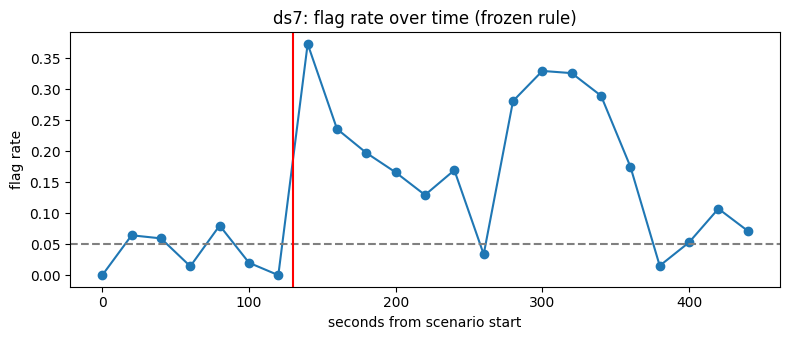

In [14]:
# ds7 evaluation: RUN ONCE with the frozen config
ds7_raw = all_df[all_df.scenario == "ds7"]
ds7_scored = rule_score(ds7_raw, baseline_final, WINDOW, STD_FLOOR)
print("Rows dropped (satellite missing from baseline):", len(ds7_raw) - len(ds7_scored))

y = ds7_scored["label"].values
s = ds7_scored["score"].values
flag = s > threshold_final
print("AUC:", round(roc_auc_score(y, s), 3))
print("FPR on ds7 normal segment (target 0.05):", round(flag[y == 0].mean(), 3))
print("Recall on ds7 attack segment:", round(flag[y == 1].mean(), 3))

# Time-resolved view: flag rate per 20 s block (red = documented attack start)
t0 = ds7_scored.t.min()
blocks = (((ds7_scored.t - t0) // 20) * 20).values
rate = pd.Series(flag).groupby(blocks).mean()
plt.figure(figsize=(8, 3.5))
plt.plot(rate.index, rate.values, marker="o")
plt.axhline(0.05, ls="--", c="gray")
plt.axvline(ONSET["ds7"] - t0, c="red")
plt.xlabel("seconds from scenario start"); plt.ylabel("flag rate")
plt.title("ds7: flag rate over time (frozen rule)")
plt.tight_layout(); plt.show()

In [15]:
# Validation report with the frozen recipe (LOSO-style): baseline = cleanStatic only,
# threshold = 95th percentile of the OTHER development scenario's normal rows
def validation_report(test_scn, calib_scn, window=25, floor=0.5, target=0.05):
    base = make_baseline(all_df[(all_df.scenario == "cleanStatic") & (all_df.label == 0)])
    calib = rule_score(all_df[(all_df.scenario == calib_scn) & (all_df.label == 0)], base, window, floor)
    test = rule_score(all_df[all_df.scenario == test_scn], base, window, floor)
    thr = np.quantile(calib["score"], 1 - target)
    y, s = test["label"].values, test["score"].values
    flag = s > thr
    return {"test": test_scn, "threshold_from": calib_scn, "threshold": round(float(thr), 3),
            "AUC": round(roc_auc_score(y, s), 3),
            "actual_FPR": round(flag[y == 0].mean(), 3),
            "recall": round(flag[y == 1].mean(), 3)}

pd.DataFrame([validation_report("ds2", "ds3"), validation_report("ds3", "ds2")])

,test,threshold_from,threshold,AUC,actual_FPR,recall
0,ds2,ds3,1.768,0.995,0.053,0.986
1,ds3,ds2,1.823,0.904,0.046,0.711


In [16]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

IF_FEATSETS = {
    "z25":      ["z_roll_mean_25"],
    "z5_25_50": ["z_roll_mean_5", "z_roll_mean_25", "z_roll_mean_50"],
}

def if_loso(test_scn, calib_scn, feat_name, target=0.05, floor=0.5, seed=42):
    feats = IF_FEATSETS[feat_name]

    # 1) Baseline and training data: cleanStatic normal rows only
    base_df = all_df[(all_df.scenario == "cleanStatic") & (all_df.label == 0)]
    b = make_baseline(base_df)
    b["cn0_sd"] = b["cn0_sd"].clip(lower=floor)
    train = add_z(base_df, b)

    # 2) Fit scaler + Isolation Forest on training features
    scaler = StandardScaler().fit(train[feats])
    model = IsolationForest(n_estimators=200, random_state=seed).fit(scaler.transform(train[feats]))

    def anomaly_score(df):
        # higher = more anomalous (negated decision_function)
        d = add_z(df, b)
        return d, -model.decision_function(scaler.transform(d[feats]))

    # 3) Threshold from a DIFFERENT scenario's normal rows
    _, calib_s = anomaly_score(all_df[(all_df.scenario == calib_scn) & (all_df.label == 0)])
    thr = np.quantile(calib_s, 1 - target)

    # 4) Evaluate on the held-out scenario
    d, s = anomaly_score(all_df[all_df.scenario == test_scn])
    y = d["label"].values
    flag = s > thr
    return {"model": "IF", "feats": feat_name, "test": test_scn,
            "AUC": round(roc_auc_score(y, s), 3),
            "actual_FPR": round(flag[y == 0].mean(), 3),
            "recall": round(flag[y == 1].mean(), 3)}

rows = []
for fn in IF_FEATSETS:
    rows.append(if_loso("ds2", "ds3", fn))
    rows.append(if_loso("ds3", "ds2", fn))
# Reference rows: the simple rule results from the previous cell
rows.append({"model": "rule", "feats": "abs(z_roll25)", "test": "ds2", "AUC": 0.995, "actual_FPR": 0.053, "recall": 0.986})
rows.append({"model": "rule", "feats": "abs(z_roll25)", "test": "ds3", "AUC": 0.904, "actual_FPR": 0.046, "recall": 0.711})
pd.DataFrame(rows)

,model,feats,test,AUC,actual_FPR,recall
0,IF,z25,ds2,0.980,0.054,0.985
1,IF,z25,ds3,0.903,0.043,0.665
2,IF,z5_25_50,ds2,0.986,0.053,0.988
3,IF,z5_25_50,ds3,0.916,0.044,0.690
4,rule,abs(z_roll25),ds2,0.995,0.053,0.986
5,rule,abs(z_roll25),ds3,0.904,0.046,0.711


In [17]:
import joblib, json
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

# FROZEN IF CONFIG - do not change after the ds7 cell below
IF_FEATS = ["z_roll_mean_5", "z_roll_mean_25", "z_roll_mean_50"]
STD_FLOOR = 0.5
TARGET_FPR = 0.05

# 1) Baseline + training data: cleanStatic normal rows only
base_df = all_df[(all_df.scenario == "cleanStatic") & (all_df.label == 0)]
b_final = make_baseline(base_df)
b_final["cn0_sd"] = b_final["cn0_sd"].clip(lower=STD_FLOOR)
train_f = add_z(base_df, b_final)

# 2) Fit scaler + Isolation Forest (same settings as the validated runs)
scaler_v2 = StandardScaler().fit(train_f[IF_FEATS])
if_v2 = IsolationForest(n_estimators=200, random_state=42).fit(scaler_v2.transform(train_f[IF_FEATS]))

# 3) Threshold from pooled ds2+ds3 normal rows. decision_function: LOWER = more anomalous,
#    so the 5th percentile gives a 5% false alarm rate (same convention as model.py)
calib_df = add_z(all_df[all_df.scenario.isin(["ds2", "ds3"]) & (all_df.label == 0)], b_final)
calib_scores = if_v2.decision_function(scaler_v2.transform(calib_df[IF_FEATS]))
thr_v2 = float(np.percentile(calib_scores, TARGET_FPR * 100))
print("IF threshold (decision_function):", round(thr_v2, 4))

# 4) Save with NEW names (v1 files stay untouched)
joblib.dump(if_v2, f"{network_dir}/detector_v2.pkl")
joblib.dump(scaler_v2, f"{network_dir}/scaler_v2.pkl")
with open(f"{network_dir}/threshold_v2.txt", "w") as f:
    f.write(str(thr_v2))
b_final.to_csv(f"{network_dir}/baseline_v2_cn0_floored.csv")
with open(f"{network_dir}/if_v2_config.json", "w") as f:
    json.dump({"features": IF_FEATS, "windows": [5, 25, 50], "std_floor": STD_FLOOR,
               "target_fpr": TARGET_FPR, "threshold": thr_v2,
               "baseline_scenario": "cleanStatic",
               "calibration_scenarios": ["ds2", "ds3"]}, f, indent=2)

# 5) Reload test: the saved files must reproduce the in-memory predictions exactly
m2 = joblib.load(f"{network_dir}/detector_v2.pkl")
s2 = joblib.load(f"{network_dir}/scaler_v2.pkl")
t2 = float(open(f"{network_dir}/threshold_v2.txt").read())
chk = add_z(all_df[all_df.scenario == "ds3"], b_final)
flag_mem = if_v2.decision_function(scaler_v2.transform(chk[IF_FEATS])) < thr_v2
flag_disk = m2.decision_function(s2.transform(chk[IF_FEATS])) < t2
print("Reload identical:", np.array_equal(flag_mem, flag_disk))

IF threshold (decision_function): -0.1551
Reload identical: True


AUC: 0.669
FPR on ds7 normal segment (target 0.05): 0.033
Recall on ds7 attack segment: 0.144


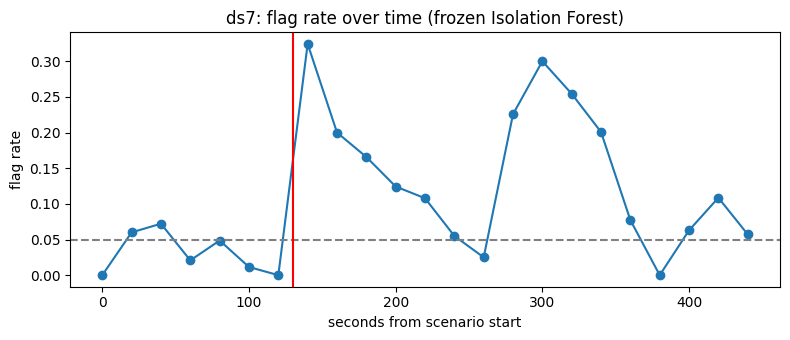

In [18]:
# ds7 evaluation of the frozen IF: RUN ONCE
ds7_if = add_z(all_df[all_df.scenario == "ds7"], b_final)
dec = if_v2.decision_function(scaler_v2.transform(ds7_if[IF_FEATS]))
y7 = ds7_if["label"].values
flag7 = dec < thr_v2
print("AUC:", round(roc_auc_score(y7, -dec), 3))
print("FPR on ds7 normal segment (target 0.05):", round(flag7[y7 == 0].mean(), 3))
print("Recall on ds7 attack segment:", round(flag7[y7 == 1].mean(), 3))

t0 = ds7_if.t.min()
rate = pd.Series(flag7).groupby((((ds7_if.t - t0) // 20) * 20).values).mean()
plt.figure(figsize=(8, 3.5))
plt.plot(rate.index, rate.values, marker="o")
plt.axhline(0.05, ls="--", c="gray"); plt.axvline(ONSET["ds7"] - t0, c="red")
plt.xlabel("seconds from scenario start"); plt.ylabel("flag rate")
plt.title("ds7: flag rate over time (frozen Isolation Forest)")
plt.tight_layout(); plt.show()

#7. V2 Conclusions & Limitations

## v2 results (frozen rule: |25-sample rolling mean of per-satellite C/N0 z-score| > 1.79)

| Scenario | Role | Target FPR | Actual FPR | Recall | AUC |
|---|---|---|---|---|---|
| ds2 | development (LOSO, threshold from ds3 normals) | 5% | 5.3% | 0.986 | 0.994 |
| ds3 | development (LOSO, threshold from ds2 normals) | 5% | 4.6% | 0.711 | 0.888 |
| ds7 | final test, run once | 5% | 3.7% | 0.185 | 0.671 |

Notes:
- ds2/ds3 were used to choose the feature set and window, so they are development results.
- On ds7 the rule mainly reacts at the documented attack onset (flag rate ~37%), then falls
  back near the normal level. Sustained detection is weak, which is expected for a
  power-matched attack when the only feature is C/N0.
- Threshold calibration is stable across scenarios (actual FPR within ~1 point of target at 5%).
- Known limitation: one feature, one receiver. GNSS-SDR data and ds7-type attacks need
  additional signals (correlator outputs, cross-checks against 5G/network PNT).